In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import fft, fftshift
from scipy.signal.windows import hann, hamming, blackman, flattop

f1, f2, f3 = 300, 300.25, 299.75   # Hz
A1 = 2; A2 = 0.1*A1; A3 = 0.01*A1
fs = 400   # Hz
N = 2000
k = np.arange(N)

In [2]:
x = (A1*np.sin(2*np.pi*f1/fs*k)
   + A2*np.sin(2*np.pi*f2/fs*k)
   + A3*np.sin(2*np.pi*f3/fs*k))

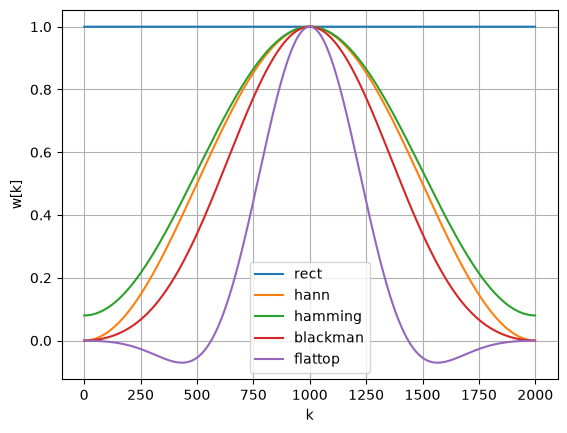

In [3]:
okna = {
    'rect': np.ones(N),
    'hann': hann(N, sym=False),
    'hamming': hamming(N, sym=False),
    'blackman': blackman(N, sym=False),
    'flattop': flattop(N, sym=False),
}
for nazwa, w in okna.items():
    plt.plot(w, label=nazwa)
plt.xlabel('k'); plt.ylabel('w[k]'); plt.legend(); plt.grid(True)
plt.show()

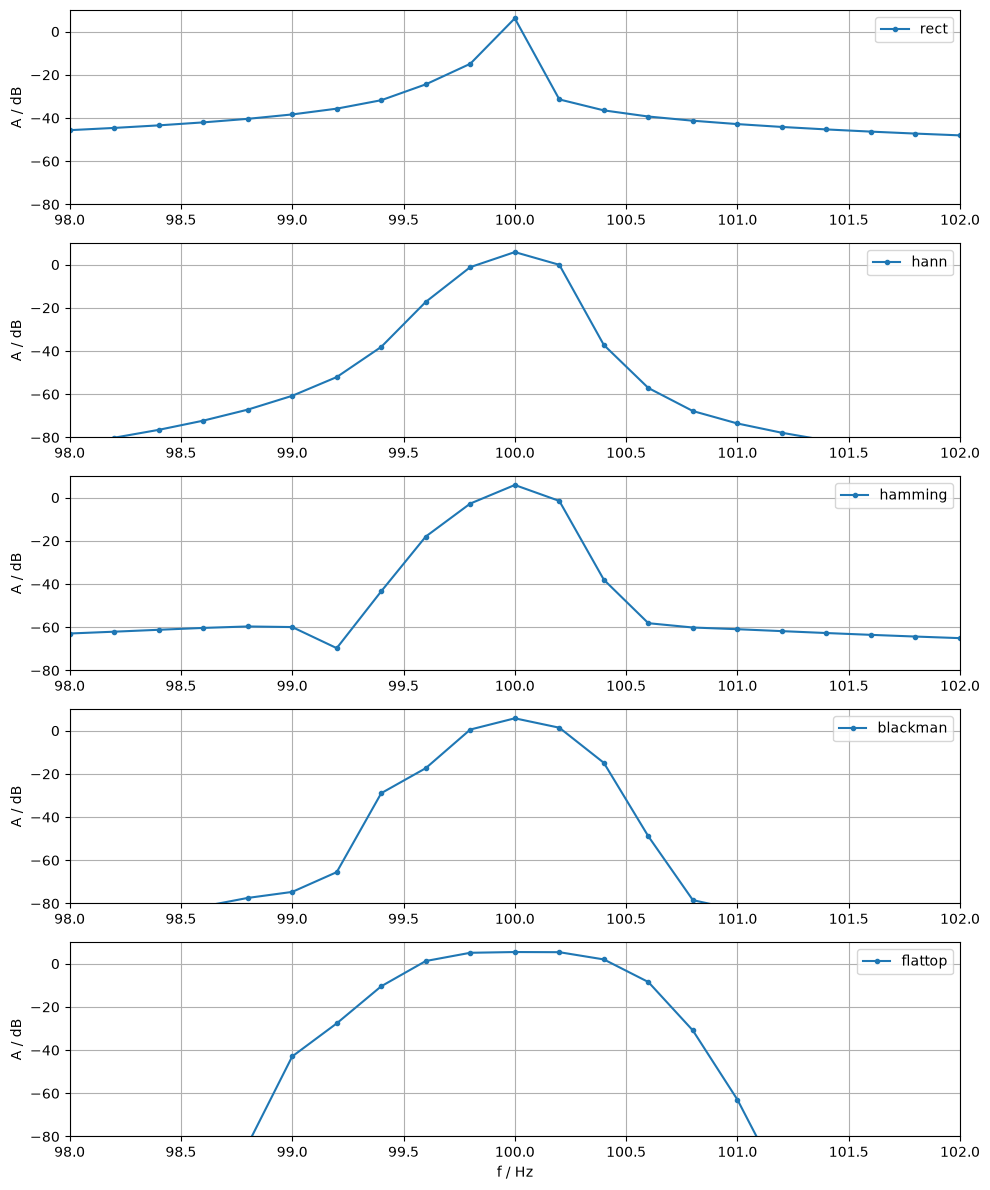

In [4]:
def fft2db(X):
    N = X.size
    Xtmp = 2/N * X
    Xtmp[0] *= 1/2
    if N % 2 == 0:
        Xtmp[N//2] /= 2
    return 20*np.log10(np.abs(Xtmp))

f = np.arange(N) * fs/N

plt.figure(figsize=(10, 12))
for i, (nazwa, w) in enumerate(okna.items(), 1):
    plt.subplot(len(okna), 1, i)
    plt.plot(f, fft2db(fft(x*w) / np.mean(w)), 'o-', ms=3, label=nazwa)
    plt.xlim(98, 102)
    plt.ylim(-80, 10)
    plt.ylabel('A / dB'); plt.legend(); plt.grid(True)
plt.xlabel('f / Hz')
plt.tight_layout()
plt.show()

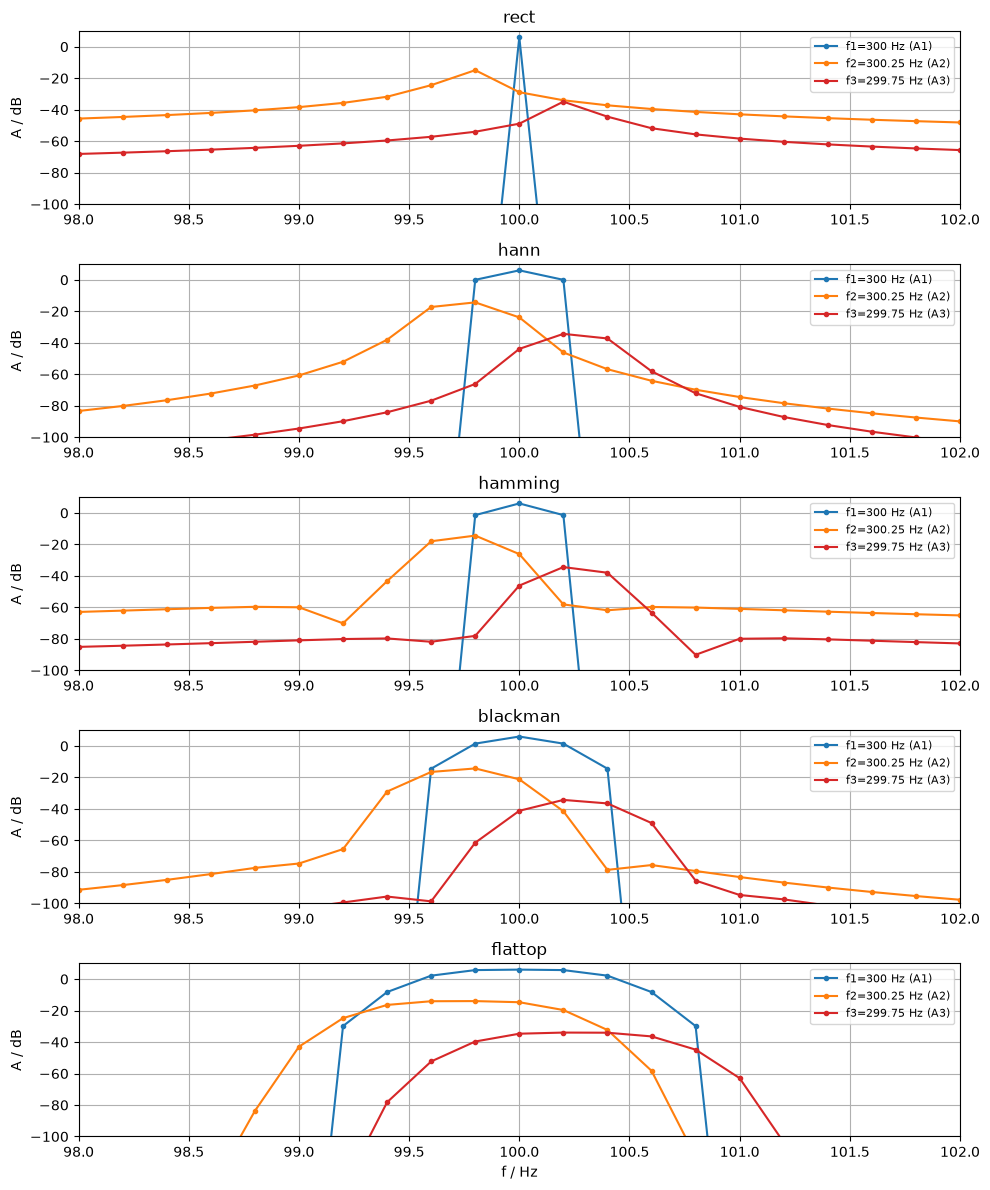

In [5]:
x1 = A1*np.sin(2*np.pi*f1/fs*k)
x2 = A2*np.sin(2*np.pi*f2/fs*k)
x3 = A3*np.sin(2*np.pi*f3/fs*k)

plt.figure(figsize=(10, 12))
for i, (nazwa, w) in enumerate(okna.items(), 1):
    plt.subplot(len(okna), 1, i)
    g = np.mean(w)
    plt.plot(f, fft2db(fft(x1*w)/g), 'C0o-', ms=3, label=f'f1={f1} Hz (A1)')
    plt.plot(f, fft2db(fft(x2*w)/g), 'C1o-', ms=3, label=f'f2={f2} Hz (A2)')
    plt.plot(f, fft2db(fft(x3*w)/g), 'C3o-', ms=3, label=f'f3={f3} Hz (A3)')
    plt.title(nazwa); plt.xlim(98, 102); plt.ylim(-100, 10)
    plt.ylabel('A / dB'); plt.legend(fontsize=8); plt.grid(True)
plt.xlabel('f / Hz')
plt.tight_layout()
plt.show()

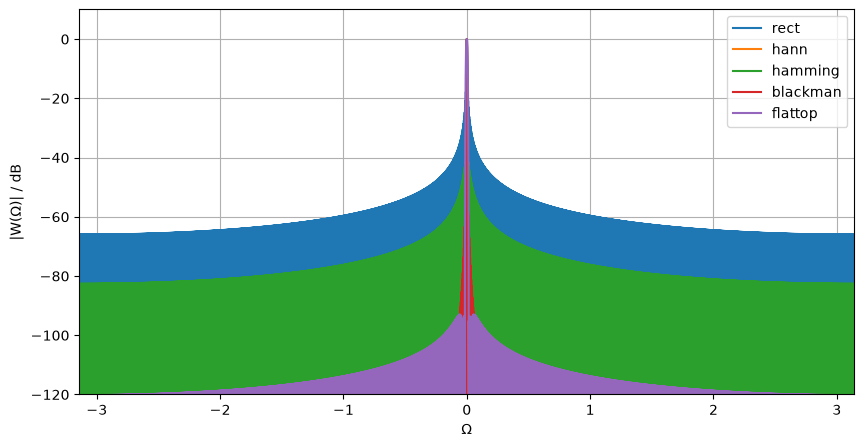

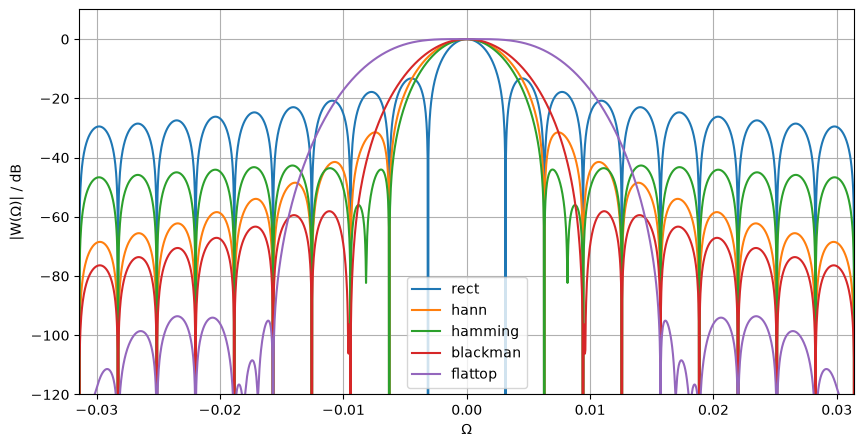

In [6]:
def winDTFTdB(w):
    N = w.size
    Nz = 100*N
    W = np.zeros(Nz); W[:N] = w
    W = np.abs(fftshift(fft(W)))
    W /= W.max()
    Omega = 2*np.pi/Nz*np.arange(Nz) - np.pi
    return Omega, 20*np.log10(W + 1e-300)

for zakres in [np.pi, np.pi/100]:      # cały zakres + zoom na listek główny
    plt.figure(figsize=(10, 5))
    for nazwa, w in okna.items():
        Om, W = winDTFTdB(w)
        plt.plot(Om, W, label=nazwa)
    plt.xlim(-zakres, zakres); plt.ylim(-120, 10)
    plt.xlabel(r'$\Omega$'); plt.ylabel(r'|W($\Omega$)| / dB')
    plt.legend(); plt.grid(True)
    plt.show()

## Interpretation of results (variant 5)

**Note - aliasing:** fs = 400 Hz, so the Nyquist frequency is 200 Hz.
The tones 300 / 300.25 / 299.75 Hz are aliased and appear in the spectrum at 100 / 99.75 / 100.25 Hz.
DFT resolution: Δf = fs/N = 0.2 Hz, while the tone spacing is only 0.25 Hz (about 1.25 bins), i.e. ΔΩ = 2π·0.25/400 ≈ 0.0039 rad.

**1. Detection of weak tones close to a strong tone**
In general, windows with low sidelobes (Blackman approx. -58 dB, flat top approx. -93 dB) are best, because the leakage of the strong tone does not mask the weak components. The rectangular window has sidelobes at −13 dB, so its leakage floor (about -40 dB) is at the level of the weak tone A3 (-40 dB) and can hide it. In this variant, however, the tones are so close that they fall inside the wide mainlobe of the Blackman and flat top windows and merge with the strong tone.

**2. Separation of closely spaced frequencies**
The rectangular window gives the best separation, because it has the narrowest mainlobe (±2π/N ≈ 0.0031). It is the only window for which the spectrum around 100 Hz is clearly asymmetric (about -15 dB at 99.8 Hz and -31 dB at 100.2 Hz), which reveals the tones A2 and A3. Hann and Hamming have a mainlobe twice as wide, Blackman three times, flat top about five times, so the three tones merge into a single peak.

**3. Influence of sidelobe level and mainlobe width**
-- A wide mainlobe means worse frequency resolution: close tones are smeared into one peak.
-High sidelobes mean more spectral leakage: the energy of a strong tone spreads over the whole spectrum and masks weak tones (leakage floor about -40 dB for rect vs. about −65 dB for Hamming).

Both properties cannot be improved at the same time - lower sidelobes always come with a wider mainlobe, so the choice of a window is a trade-off. The flat top window has the widest mainlobe, but its almost flat peak gives the most accurate amplitude reading.

**4. Why f1, f2 and f3 are represented differently**
f1 = 300 Hz (-> 100 Hz) contains an integer number of periods in N samples and falls exactly on DFT bin 500 (100 / 0.2). With the rectangular window it gives a single clean line without leakage, because all other DFT bins coincide with the zeros of the window spectrum. f2 and f3 lie 0.25 bin away from the DFT bins. They do not fit an integer number of periods in the window, so the periodic extension has a discontinuity at the window boundary and their energy leaks into all neighbouring bins (spectral leakage). Thus a frequency shift of only 0.25 Hz changes the spectral picture completely.

**Conclusion:** for tones this close (1.25 bins) no window separates them clearly; the rectangular window shows them best as an asymmetry of the peak, while low-sidelobe windows reduce leakage but merge the tones. Better separation requires a longer observation time, e.g. N = 8000 -> Δf = 0.05 Hz (5 bins between the tones).